In [7]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("D:\\NLP\\Project\\Loan_Advisor_Chatbot\\Data\\raw\\loan_approval_dataset.csv")

# Display dataset shape
print("Dataset shape:", df.shape)

# Display first five rows
display(df.head())

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())
print(df.columns.tolist())

# Check target distribution
print("\nLoan status distribution:")
print(df[" loan_status"].value_counts(dropna=False))

Dataset shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected



Column names:
['loan_id', ' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']

Data types:
loan_id                       int64
 no_of_dependents             int64
 education                   object
 self_employed               object
 income_annum                 int64
 loan_amount                  int64
 loan_term                    int64
 cibil_score                  int64
 residential_assets_value     int64
 commercial_assets_value      int64
 luxury_assets_value          int64
 bank_asset_value             int64
 loan_status                 object
dtype: object

Missing values:
loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_sco

In [8]:
# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


In [9]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check duplicate loan IDs
print("Duplicate loan IDs:", df["loan_id"].duplicated().sum())

# Check target distribution
print("\nLoan status distribution:")
print(df["loan_status"].value_counts())

# Check target proportions
print("\nLoan status percentage:")
print(
    (df["loan_status"].value_counts(normalize=True) * 100).round(2)
)

Missing values:
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Duplicate rows: 0
Duplicate loan IDs: 0

Loan status distribution:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

Loan status percentage:
loan_status
Approved    62.22
Rejected    37.78
Name: proportion, dtype: float64


In [10]:
# Summary statistics for numerical columns
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
loan_id,4269.0,2.135000e+03,1.232498e+03,1.0,1068.0,2135.0,3202.0,4269.0
no_of_dependents,4269.0,2.498712e+00,1.695910e+00,0.0,1.0,3.0,4.0,5.0
income_annum,4269.0,5.059124e+06,2.806840e+06,200000.0,2700000.0,5100000.0,7500000.0,9900000.0
loan_amount,4269.0,1.513345e+07,9.043363e+06,300000.0,7700000.0,14500000.0,21500000.0,39500000.0
loan_term,4269.0,1.090045e+01,5.709187e+00,2.0,6.0,10.0,16.0,20.0
cibil_score,4269.0,5.999361e+02,1.724304e+02,300.0,453.0,600.0,748.0,900.0
residential_assets_value,4269.0,7.472617e+06,6.503637e+06,-100000.0,2200000.0,5600000.0,11300000.0,29100000.0
commercial_assets_value,4269.0,4.973155e+06,4.388966e+06,0.0,1300000.0,3700000.0,7600000.0,19400000.0
luxury_assets_value,4269.0,1.512631e+07,9.103754e+06,300000.0,7500000.0,14600000.0,21700000.0,39200000.0
bank_asset_value,4269.0,4.976692e+06,3.250185e+06,0.0,2300000.0,4600000.0,7100000.0,14700000.0


In [11]:
# Separate input features and target variable

X = df.drop(columns=["loan_id", "loan_status"])
y = df["loan_status"]

# Display feature columns
print("Feature columns:")
print(X.columns.tolist())

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

# Check target labels
print("\nTarget labels:")
print(y.unique())

Feature columns:
['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']

Features shape: (4269, 11)
Target shape: (4269,)

Target labels:
[' Approved' ' Rejected']


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (3415, 11)
Testing features: (854, 11)

Training target distribution:
loan_status
Approved    2125
Rejected    1290
Name: count, dtype: int64

Testing target distribution:
loan_status
Approved    531
Rejected    323
Name: count, dtype: int64


In [13]:
# Convert categorical columns into numeric columns

X_train_encoded = pd.get_dummies(
    X_train,
    columns=["education", "self_employed"],
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=["education", "self_employed"],
    dtype=int
)

# Ensure test columns match training columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

print("\nEncoded columns:")
print(X_train_encoded.columns.tolist())

display(X_train_encoded.head())

Encoded training shape: (3415, 13)
Encoded testing shape: (854, 13)

Encoded columns:
['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'education_ Graduate', 'education_ Not Graduate', 'self_employed_ No', 'self_employed_ Yes']


,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,education_ Graduate,education_ Not Graduate,self_employed_ No,self_employed_ Yes
1224,0,9800000,23900000,14,459,1000000,13400000,21100000,7200000,1,0,0,1
478,3,3600000,8600000,8,790,5400000,5900000,9800000,5200000,0,1,0,1
3065,2,2000000,4000000,14,502,4900000,1500000,5400000,1300000,0,1,1,0
326,2,3900000,11300000,12,516,3100000,0,10400000,4600000,0,1,0,1
2991,3,2300000,8500000,12,557,3600000,1400000,6200000,1300000,0,1,1,0


In [14]:
# Remove extra spaces from target labels
y_train = y_train.str.strip()
y_test = y_test.str.strip()

print("Training labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Training labels:
loan_status
Approved    2125
Rejected    1290
Name: count, dtype: int64

Testing labels:
loan_status
Approved    531
Rejected    323
Name: count, dtype: int64


In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Identify original numerical columns
numeric_cols = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

# Create copies so the encoded data remains unchanged
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

# Initialize scaler
scaler = StandardScaler()

# Fit only on training data, then transform both sets
X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train_encoded[numeric_cols]
)

X_test_scaled[numeric_cols] = scaler.transform(
    X_test_encoded[numeric_cols]
)

# Train model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_scaled, y_train)

# Predict test results
y_pred_lr = lr_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Accuracy: 0.9227
Accuracy percentage: 92.27 %

Classification Report:
              precision    recall  f1-score   support

    Approved       0.93      0.95      0.94       531
    Rejected       0.92      0.88      0.90       323

    accuracy                           0.92       854
   macro avg       0.92      0.91      0.92       854
weighted avg       0.92      0.92      0.92       854

Confusion Matrix:
[[283  40]
 [ 26 505]]


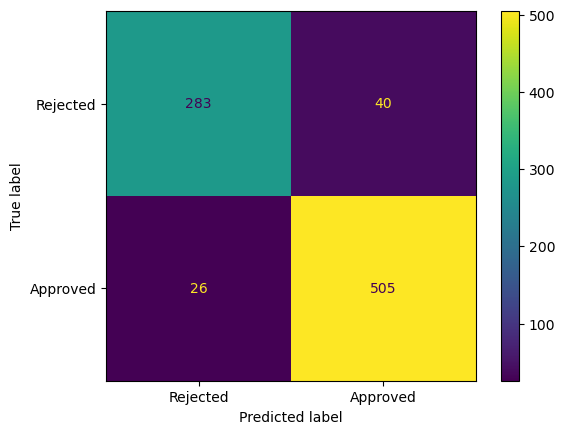

In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Accuracy
accuracy = accuracy_score(y_test, y_pred_lr)
print("Accuracy:", round(accuracy, 4))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

# Precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=["Rejected", "Approved"]
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
)
disp.plot()
plt.show()

In [17]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train model
dt_model.fit(X_train_encoded, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test_encoded)

# Evaluate model
print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, y_pred_dt) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_dt,
    labels=["Rejected", "Approved"]
))

Decision Tree Accuracy: 97.78 %

Classification Report:
              precision    recall  f1-score   support

    Approved       0.99      0.97      0.98       531
    Rejected       0.95      0.99      0.97       323

    accuracy                           0.98       854
   macro avg       0.97      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854


Confusion Matrix:
[[320   3]
 [ 16 515]]


In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_encoded, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test_encoded)

# Evaluate model
print(
    "Random Forest Accuracy:",
    round(accuracy_score(y_test, y_pred_rf) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_rf,
        labels=["Rejected", "Approved"]
    )
)

Random Forest Accuracy: 98.24 %

Classification Report:
              precision    recall  f1-score   support

    Approved       0.98      1.00      0.99       531
    Rejected       0.99      0.96      0.98       323

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854


Confusion Matrix:
[[310  13]
 [  2 529]]


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            pos_label="Approved"
        ),
        "Recall": recall_score(
            y_test, predictions,
            pos_label="Approved"
        ),
        "F1 Score": f1_score(
            y_test, predictions,
            pos_label="Approved"
        )
    })

results_df = pd.DataFrame(results)

# Display metrics as percentages
metric_cols = ["Accuracy", "Precision", "Recall", "F1 Score"]
results_df[metric_cols] = (
    results_df[metric_cols] * 100
).round(2)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,98.24,97.60,99.62,98.60
1,Decision Tree,97.78,99.42,96.99,98.19
2,Logistic Regression,92.27,92.66,95.10,93.87


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            pos_label="Approved"
        ),
        "Recall": recall_score(
            y_test, predictions,
            pos_label="Approved"
        ),
        "F1 Score": f1_score(
            y_test, predictions,
            pos_label="Approved"
        )
    })

results_df = pd.DataFrame(results)

# Display metrics as percentages
metric_cols = ["Accuracy", "Precision", "Recall", "F1 Score"]
results_df[metric_cols] = (
    results_df[metric_cols] * 100
).round(2)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,98.24,97.60,99.62,98.60
1,Decision Tree,97.78,99.42,96.99,98.19
2,Logistic Regression,92.27,92.66,95.10,93.87


In [21]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate Random Forest across five folds
cv_scores = cross_val_score(
    rf_model,
    X_train_encoded,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Accuracy for each fold:")
print((cv_scores * 100).round(2))

print("\nMean cross-validation accuracy:",
      round(cv_scores.mean() * 100, 2), "%")

print("Standard deviation:",
      round(cv_scores.std() * 100, 2), "percentage points")

Accuracy for each fold:
[97.95 96.93 97.95 98.24 98.68]

Mean cross-validation accuracy: 97.95 %
Standard deviation: 0.58 percentage points


In [22]:
import joblib
from pathlib import Path

# Create a folder for saved models
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the trained Random Forest model
joblib.dump(
    rf_model,
    model_dir / "loan_approval_rf.pkl"
)

# Save the exact feature-column order used during training
joblib.dump(
    X_train_encoded.columns.tolist(),
    model_dir / "loan_approval_features.pkl"
)

print("Random Forest model saved successfully.")
print("Feature columns saved successfully.")
print("Model folder:", model_dir.resolve())

Random Forest model saved successfully.
Feature columns saved successfully.
Model folder: D:\NLP\Project\Loan_Advisor_Chatbot\models


In [23]:
# Take one applicant from the test set
sample_applicant = X_test_encoded.iloc[[0]]

# Predict loan status
predicted_status = rf_model.predict(sample_applicant)[0]

# Predict class probabilities
probabilities = rf_model.predict_proba(sample_applicant)[0]

print("Predicted loan status:", predicted_status)

print("\nClass probabilities:")
for label, probability in zip(
    rf_model.classes_,
    probabilities
):
    print(f"{label}: {probability * 100:.2f}%")

Predicted loan status: Approved

Class probabilities:
Approved: 96.68%
Rejected: 3.32%


In [24]:
import pandas as pd

# Features expected by the trained model
feature_columns = X_train_encoded.columns.tolist()

def predict_loan_status(applicant_data):
    """
    Predict loan status from an applicant's structured details.

    applicant_data must contain all features used during training.
    """

    # Convert applicant details into a one-row DataFrame
    applicant_df = pd.DataFrame(
        [applicant_data]
    )

    # Apply the same categorical encoding used during training
    applicant_df = pd.get_dummies(
        applicant_df,
        columns=["education", "self_employed"],
        dtype=int
    )

    # Match training columns and their order
    applicant_df = applicant_df.reindex(
        columns=feature_columns,
        fill_value=0
    )

    # Predict status
    prediction = rf_model.predict(applicant_df)[0]

    # Get estimated class probabilities
    probabilities = rf_model.predict_proba(applicant_df)[0]

    probability_dict = {
        label: round(float(probability) * 100, 2)
        for label, probability in zip(
            rf_model.classes_,
            probabilities
        )
    }

    return {
        "predicted_status": prediction,
        "class_probabilities": probability_dict
    }

In [25]:
sample_applicant = {
    "no_of_dependents": 2,
    "education": "Graduate",
    "self_employed": "No",
    "income_annum": 9600000,
    "loan_amount": 29900000,
    "loan_term": 12,
    "cibil_score": 778,
    "residential_assets_value": 2400000,
    "commercial_assets_value": 17600000,
    "luxury_assets_value": 22700000,
    "bank_asset_value": 8000000
}

result = predict_loan_status(sample_applicant)

print("Predicted status:", result["predicted_status"])
print("Estimated class probabilities:")

for label, probability in result["class_probabilities"].items():
    print(f"{label}: {probability}%")

Predicted status: Approved
Estimated class probabilities:
Approved: 93.07%
Rejected: 6.93%


In [26]:
import joblib
from pathlib import Path

# Create models folder in your project
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save trained Random Forest model
joblib.dump(
    rf_model,
    model_dir / "loan_approval_rf.pkl"
)

# Save the exact training feature columns
joblib.dump(
    X_train_encoded.columns.tolist(),
    model_dir / "loan_approval_features.pkl"
)

print("Model and feature columns saved successfully!")


Model and feature columns saved successfully!
